# 02b. KV 공유, 반납, 되감기 (Part 2 뒤 절반)

앞 노트북 `02a`는 요청 한 건이 block을 받아 slot에 KV를 쓰는 데까지 봤습니다. 이 노트북은 그다음을 다룹니다. block을 두 요청이 같이 쓸 수 있는가, 요청이 끝나면 block은 어디로 가는가, 모자라면 누가 양보하는가, 틀린 draft token이 쓴 KV는 어떻게 되는가. 끝에서는 이 규칙들이 GLM-5.3-Flash처럼 층 종류가 섞인 모델에서 어떻게 넓어지는지 봅니다.

기준 소스는 vLLM v0.32.0(커밋 `5df63a7`)입니다. 사실에는 근거 ID(`P2-40` 형식)를 붙였고, 코드 위치는 그 커밋의 permalink입니다.

## 학습 목표

- `ref_cnt`로 공유와 반납을 설명한다.
- free queue의 앞과 뒤 규칙으로 eviction 순서를 예측한다.
- hash 사슬과 salt, 적중 상한을 손으로 계산한다.
- preempt가 항상 처음부터 다시 계산하는 것은 아니라는 점을 조건과 함께 말한다.
- draft token의 되감기와 덮어쓰기를 `num_computed_tokens`로 추적한다.
- GLM-5.3-Flash에 왜 hybrid KV 관리가 필요한지 층 종류로 말한다.

## 수업 시간표

| 절 | 내용 | 분 |
|---|---|---:|
| 0 | 앞 노트북에서 넘어온 것 | 2 |
| 1 | `ref_cnt`: 공유와 반납 | 6 |
| 2 | free queue와 eviction | 7 |
| 3 | hash 사슬, salt, 적중 상한 | 8 |
| 4 | preempt와 recompute | 5 |
| 5 | speculative decoding과 MTP | 8 |
| 6 | hybrid KV와 GLM-5.3-Flash | 6 |
| 7 | 직접 해보기, 확인 질문, 정리 | 3 |

## 호출 규모

모델 호출 0회, 유료 API 호출 0회, 키와 GPU가 필요 없습니다. 모든 코드 셀은 수업용 시뮬레이터 `vllm_lab`과 저장된 결과 파일 `data/reference_kv.json`만 읽습니다. 네트워크를 쓰지 않습니다.

## 0. 앞 노트북에서 넘어온 것

여정 지도로 보면 이 노트북은 네 정거장에 걸쳐 있습니다.

| 정거장 | 이 노트북에서 보는 것 |
|---|---|
| 5 schedule | prefix cache 조회, block 할당, 모자랄 때의 preempt |
| 6 forward·sampling | draft token의 KV 쓰기와 검증 |
| 7 결과 반영 | 틀린 draft 되감기 |
| 9 반납 | 참조 해제, free queue 복귀 |

`02a`에서 가져오는 것은 slot 식 `block_table[position // block_size] * block_size + position % block_size`와 "`KVCacheBlock`은 값이 아니라 metadata다"라는 두 가지입니다(P2-06, P2-16). 요청 이름은 `doc`, `faq`, `chat`이고 `doc`의 프롬프트 54 token은 수업이 정한 값입니다. 실제 tokenizer 결과가 아닙니다.

이것은 vLLM이 아니라 수업용 모델입니다. `vllm_lab.kv_sim`은 v0.32.0의 규칙을 한 group, `block_size == hash_block_size`로 줄여 같은 순서로 실행하고, KV 값 대신 표지만 남깁니다. 시뮬레이터 출력은 "vLLM이 이렇게 동작했다"가 아닙니다. 모델링하지 않은 것은 아래 셀이 출력합니다. 실제 클래스와 맞춰 본 결과는 3절에서 범위와 함께 따로 봅니다.

**왜 이렇게 설계했나.** block 배치(`02a`)와 block 재사용(`02b`)을 두 노트북으로 나눈 것은 수업의 구성이고 vLLM의 설계가 아닙니다.

In [1]:
from vllm_lab import DATA_DIR, VLLM_VERSION, view
from vllm_lab.kv_sim import (NOT_MODELED, GroupSpec, HybridPoolToy, KVManagerSim, agreed_hit,
                             glm_like_groups, reference_rows, request_block_hashes, slot_id)


def toks(start, n):
    """수업용 가짜 token ID. 실제 tokenizer 결과가 아닙니다."""
    return list(range(start, start + n))


DOC_PROMPT, CHAT_PROMPT, FAQ_PROMPT = toks(1000, 54), toks(3000, 34), toks(4000, 20)
DOC_OUTPUT = toks(2000, 8)


def fresh(num_blocks=12):
    """chat이 [1, 2, 3], doc이 [4, 5, 6, 7]을 쥔 출발 상태."""
    mgr = KVManagerSim(num_blocks)
    chat, doc = mgr.add_request("chat", CHAT_PROMPT), mgr.add_request("doc", DOC_PROMPT)
    mgr.schedule(chat)
    mgr.schedule(doc)
    return mgr, chat, doc


def block_rows(mgr):
    """ref_cnt나 hash가 있는 block만 표로."""
    return view.table([{"block_id": c["block_id"], "state": c["state"], "ref_cnt": c["ref_cnt"],
                        "owners": c["label"], "hash": c["block_hash"] or "-"}
                       for c in mgr.snapshot()
                       if c["state"] != "null" and (c["ref_cnt"] or c["block_hash"])])


print("기준 소스 vLLM", VLLM_VERSION, "/ 수업용 모델이 다루지 않는 것:")
for line in NOT_MODELED:
    print(" -", line)

기준 소스 vLLM 0.32.0 / 수업용 모델이 다루지 않는 것:
 - watermark(대기 중이거나 preempt된 요청에 남겨 두는 여유 block)는 모델링하지 않았다. vllm/v1/core/kv_cache_manager.py:512-516
 - scheduler_reserve_full_isl(기본 True)은 모델링하지 않았다. vLLM은 새 요청의 전체 입력이 들어갈 free block이 없으면 들여보내지 않지만 schedule은 첫 chunk에 필요한 block만 보고 들여보낸다. vllm/config/scheduler.py:190, vllm/v1/core/sched/scheduler.py:1270, vllm/v1/core/kv_cache_manager.py:522-539
 - sliding window와 skipped block은 KVManagerSim에 없다. HybridPoolToy가 block 수 규칙만 장난감으로 보인다.
 - KV connector(외부 KV 전송)와 외부 계산 token은 모델링하지 않았다.
 - 마지막 partial block 등록(partial tail 등록)은 모델링하지 않았다. 꽉 차지 않은 block은 hash가 없다.
 - max_model_len 상한(allocate_slots의 min(..., max_model_len))은 적용하지 않았다.
 - hash_block_size와 group block_size의 분리는 모델링하지 않았다. 둘이 같은 한 group만 있다.
 - 실제 KV 값은 없다. slot_contents는 어느 요청의 몇 번째 token이 쓰였는지 보여 주는 표지다.
 - 실제 hash 값은 vLLM과 다르다(sha256 앞 12자). 같은 token이면 같은 hash라는 구조만 같다.
 - LoRA, 멀티모달, prompt embeds의 extra key와 copy-on-write(partial hit)는 모델링하지 않았다.
 - pool을 직접 두 번 free하면 ValueError

## 1. `ref_cnt`: 공유와 반납

두 요청의 프롬프트 앞부분이 같으면 KV도 같으니 block을 같이 쓸 수 있습니다. 그러면 바로 다음 질문이 나옵니다. 한 요청이 끝났을 때 그 block을 돌려줘도 되는가. 이 판단을 `KVCacheBlock`의 정수 하나가 맡습니다. `ref_cnt`는 지금 이 block을 쥐고 있는 요청의 수입니다(P2-40).

| 언제 | 함수 | `ref_cnt` | 코드 |
|---|---|---|---|
| 새 block을 받을 때 | `get_new_blocks` | 0에서 1로 | [`block_pool.py:666`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/block_pool.py#L666), [`block_pool.py:691`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/block_pool.py#L691) |
| prefix hit로 같이 쓸 때 | `touch` | 1 증가. 0이었으면 free queue 중간에서 먼저 뺀다 | [`block_pool.py:752`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/block_pool.py#L752), [`block_pool.py:764`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/block_pool.py#L764) |
| 요청이 놓을 때 | `free_blocks` | 1 감소. 0이 된 block만 queue로 간다 | [`block_pool.py:774`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/block_pool.py#L774), [`block_pool.py:791`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/block_pool.py#L791) |

여기서 놓치기 쉬운 점이 둘 있습니다. `ref_cnt`가 0이 되어도 GPU의 KV 값은 지우지 않습니다. block에 붙은 hash도 지우지 않습니다(P2-38). 반납은 "이제 다른 요청이 가져가도 된다"는 표시일 뿐입니다.

**공식 문서.** 문서는 `touch`를 참조 수를 올리고, 다른 요청이 쓰지 않던 block이면 free queue에서 빼서 쫓겨나지 않게 하는 일로 설명합니다([`prefix_caching.md:146`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/prefix_caching.md#L146), P2-31).

**직접 관찰.** `doc`이 54 token을 계산한 뒤, 같은 프롬프트의 `faq2`를 넣습니다. `doc`은 끝나지 않은 상태입니다.

In [2]:
mgr, chat, doc = fresh()
faq2 = mgr.add_request("faq2", DOC_PROMPT)
shared = mgr.schedule(faq2)
display(view.table([shared.to_row()], ["request_id", "hit_tokens", "hit_block_ids", "new_block_ids", "block_table"]))
block_rows(mgr)

,request_id,hit_tokens,hit_block_ids,new_block_ids,block_table
0,faq2,48,"[4, 5, 6]",[8],"[4, 5, 6, 8]"


,block_id,state,ref_cnt,owners,hash
0,1,used,1,chat,12e2bf43a339
1,2,used,1,chat,8f16c2ef4452
2,3,used,1,chat,-
3,4,shared,2,doc+faq2,f0882bf4e8d5
4,5,shared,2,doc+faq2,a20732605fb0
5,6,shared,2,doc+faq2,5d224dbf811f
6,7,used,1,doc,-
7,8,used,1,faq2,-


**관찰할 것.** 아래쪽 표의 `ref_cnt` 칸과 `owners` 칸을 block별로 읽으세요. `doc`과 `faq2`의 block table에서 같은 ID와 다른 ID를 찾고, `hash` 칸이 `-`인 block이 그 차이와 어떻게 이어지는지 적으세요.

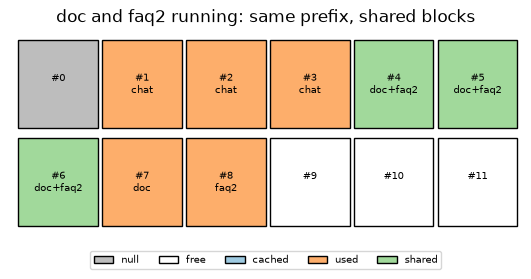

In [3]:
view.block_grid(mgr.snapshot(), ncols=6, title="doc and faq2 running: same prefix, shared blocks")

이제 두 요청을 차례로 끝냅니다. 반납 경로는 scheduler에서 시작해 pool에서 끝납니다. `_free_request`([`scheduler.py:2714`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L2714))가 `_free_blocks`([`scheduler.py:2746`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L2746))를 부르고, `KVCacheManager.free`([`kv_cache_manager.py:620`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_manager.py#L620))가 coordinator를 거쳐 group manager로 내려가며, 마지막으로 `BlockPool.free_blocks`가 참조를 풉니다(P2-38, P1-45). 다음 셀은 이 경로를 그림으로, 그다음 셀은 반납할 때마다 바뀌는 값을 표로 보여 줍니다.

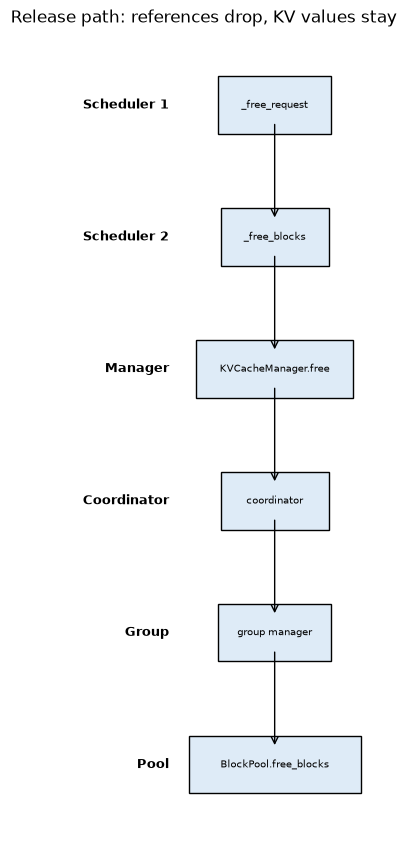

In [4]:
view.lane_diagram(
    {"Scheduler 1": ["_free_request"], "Scheduler 2": ["_free_blocks"], "Manager": ["KVCacheManager.free"],
     "Coordinator": ["coordinator"], "Group": ["group manager"], "Pool": ["BlockPool.free_blocks"]},
    [("_free_request", "_free_blocks", ""), ("_free_blocks", "KVCacheManager.free", ""),
     ("KVCacheManager.free", "coordinator", ""), ("coordinator", "group manager", ""),
     ("group manager", "BlockPool.free_blocks", "")],
    title="Release path: references drop, KV values stay")

In [5]:
def stage(name):
    return {"stage": name, "ref_cnts": mgr.ref_cnts(), "free_queue": mgr.free_queue_ids(),
            "cached_block_ids": mgr.cached_block_ids()}


rows = [stage("doc, faq2 running")]
mgr.free(doc)
rows.append(stage("doc freed"))
mgr.free(faq2)
rows.append(stage("faq2 freed"))
view.table(rows)

,stage,ref_cnts,free_queue,cached_block_ids
0,"doc, faq2 running","[[1, 1], [2, 1], [3, 1], [4, 2], [5, 2], [6, 2], [7, 1], [8, 1]]","[9, 10, 11]","[1, 2, 4, 5, 6]"
1,doc freed,"[[1, 1], [2, 1], [3, 1], [4, 1], [5, 1], [6, 1], [8, 1]]","[7, 9, 10, 11]","[1, 2, 4, 5, 6]"
2,faq2 freed,"[[1, 1], [2, 1], [3, 1]]","[8, 7, 9, 10, 11, 6, 5, 4]","[1, 2, 4, 5, 6]"


`doc`을 반납한 직후 행과 `faq2`까지 반납한 행을 비교해 보세요. 같이 쓰던 block은 한 요청이 놓아도 queue로 가지 않고, 혼자 쥐던 block은 바로 갑니다. 마지막 행에서 `cached_block_ids`가 비지 않는다는 것도 봐 두세요. 이 행이 "반납해도 다음 요청이 적중할 수 있다"의 출발점입니다.

반납을 미루는 경로도 둘 있습니다. KV connector가 block을 보내는 중이면 `delay_free_blocks`로 미룹니다([`scheduler.py:2741`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L2741)). batch가 겹쳐 도는 구성(`max_concurrent_batches > 1`, 즉 async scheduling이나 PP)이면서 KV connector가 consumer일 때만([`scheduler.py:186`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L186)), 아직 도는 step이 그 block에 쓰는 중일 수 있어서 안전한 step까지 미룹니다([`scheduler.py:2762`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L2762), P2-39). async scheduling만 켰다고 미루지는 않습니다. 시뮬레이터에는 이 지연이 없습니다.

**왜 이렇게 설계했나.** `touch`의 코드 주석은 `ref_cnt`가 0이면 free 목록에 있는 eviction 후보이므로 뺀다고 적습니다. 즉 `ref_cnt`와 free queue 소속이 같은 사실의 두 얼굴입니다. 공유가 실제로 쓸모 있는 사례도 있습니다. 생성 중에 새 메시지가 오면 서버에는 별도의 새 요청이므로, 앞 요청이 이미 hash를 붙인 꽉 찬 block을 `ref_cnt`만 올려 같이 씁니다(P2-48).

## 2. free queue와 eviction

`ref_cnt`가 0이 된 block은 어디에 놓일까요. 놓이는 자리가 다음 재사용 순서를 정하므로 이 자리가 곧 cache 정책입니다.

`FreeKVCacheBlockQueue`는 Python `deque`가 아니라 block 안의 포인터로 엮은 이중 연결 리스트입니다([`kv_cache_utils.py:246`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L246)). 앞에서 꺼내는 것 말고 일이 셋 더 있습니다. 중간 제거 `remove`([`kv_cache_utils.py:380`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L380))는 `touch`가 쓰고, 앞쪽 삽입 `prepend_n`([`kv_cache_utils.py:426`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L426))과 뒤쪽 삽입 `append_n`([`kv_cache_utils.py:447`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L447))은 반납이 씁니다(P2-09).

규칙은 두 줄입니다.

1. **hash가 없는 block은 앞으로 간다.** prefix cache로 다시 찾을 일이 없으니 먼저 재사용합니다([`block_pool.py:794`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/block_pool.py#L794)).
2. **hash가 있는 block은 뒤로 간다.** 가능한 한 늦게 재사용합니다([`block_pool.py:797`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/block_pool.py#L797), P2-10).

여기에 순서 규칙 하나가 더 붙습니다. 한 요청 안에서는 block을 꼬리부터 역순으로 반납합니다([`single_type_kv_cache_manager.py:589`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/single_type_kv_cache_manager.py#L589), [`kv_cache_manager.py:620`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_manager.py#L620), P2-11).

**공식 문서.** 문서는 포인터를 `KVCacheBlock`에 직접 둔 이유로 중간 원소를 O(1)에 옮길 수 있다는 점과 감싸는 객체가 필요 없다는 점을 듭니다([`prefix_caching.md:124`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/prefix_caching.md#L124)). 역순 반납은 문서도 적습니다([`prefix_caching.md:198`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/prefix_caching.md#L198)). 꼬리 block은 hash에 넣는 token이 더 많아 다른 요청이 재사용할 가능성이 낮으니 먼저 쫓겨나야 한다는 설명입니다. hash 없는 block을 앞에 두는 구분은 문서에 없고 위 코드와 주석이 근거입니다.

**직접 관찰.** 고정 예제 E3입니다. `doc`이 생성까지 마쳐 전체 62 token이고 block table은 `[4, 5, 6, 7]`, `chat`은 `[1, 2, 3]`을 계속 쥐고 있습니다. 꽉 찬 block만 hash를 얻으므로 앞의 3개만 hash가 있습니다.

**먼저 예측하세요.** `doc`을 반납한 직후 다음 요청이 새 block 3개를 받습니다. 어떤 ID 세 개를 어떤 순서로 받을까요? 그리고 hash가 있는 block 가운데 가장 먼저 쫓겨나는 ID는 무엇일까요? 두 답을 적은 뒤 실행하세요.

In [6]:
def e3_state(num_blocks=12):
    """doc 전체 62 token, 계산 61 token. 마지막으로 뽑은 token은 아직 입력으로 넣지 않았다."""
    mgr, chat, doc = fresh(num_blocks)
    mgr.append_output(doc, DOC_OUTPUT)
    mgr.schedule(doc, 7)
    return mgr, chat, doc


mgr, chat, doc = e3_state()
display(block_rows(mgr))
mgr.free(doc)
queue = mgr.free_queue_ids()
display(view.table([{"queue_position": i, "block_id": b, "has_hash": b in mgr.cached_block_ids()}
                    for i, b in enumerate(queue)]))
next_request = mgr.add_request("next", toks(5000, 48))
view.table([mgr.schedule(next_request).to_row()], ["request_id", "new_block_ids", "evicted_block_ids"])

,block_id,state,ref_cnt,owners,hash
0,1,used,1,chat,12e2bf43a339
1,2,used,1,chat,8f16c2ef4452
2,3,used,1,chat,-
3,4,used,1,doc,f0882bf4e8d5
4,5,used,1,doc,a20732605fb0
5,6,used,1,doc,5d224dbf811f
6,7,used,1,doc,-


,queue_position,block_id,has_hash
0,0,7,False
1,1,8,False
2,2,9,False
3,3,10,False
4,4,11,False
5,5,6,True
6,6,5,True
7,7,4,True


,request_id,new_block_ids,evicted_block_ids
0,next,"[7, 8, 9]",[]


**관찰할 것.** `queue_position`이 앞쪽인 칸과 뒤쪽인 칸에서 `doc`이 쥐던 네 block이 각각 어디에 있는지 찾고, 예측과 비교하세요. 아직 쓴 적 없는 block과 `doc`의 block 사이의 순서도 읽으세요.

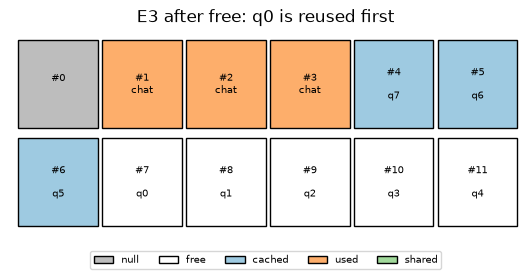

In [7]:
mgr, chat, doc = e3_state()
mgr.free(doc)
view.block_grid(mgr.snapshot(), ncols=6, title="E3 after free: q0 is reused first",
                mark={b: f"q{i}" for i, b in enumerate(mgr.free_queue_ids())})

같은 일을 event로 보면 순서가 더 분명합니다. 다음 표는 `doc`의 event만 추린 것입니다. 표의 `kind`에서 `hash_register`가 어떤 block까지 나오는지, 마지막 두 행의 `free_front`와 `free_back`에 어떤 block ID가 어떤 순서로 들어 있는지 읽으세요. `detail`의 `block_hash`는 sha256 앞 12자라서 vLLM의 값과 다릅니다.

In [8]:
view.trace_table([e for e in mgr.events if e["request_id"] == "doc" and e["kind"] != "alloc"])

,step,actor,kind,request_id,detail
0,2,KVManagerSim,hit,doc,"{""hit_tokens"": 0, ""block_ids"": [], ""max_hit_tokens"": 53}"
1,2,BlockPool,hash_register,doc,"{""block_id"": 4, ""block_hash"": ""f0882bf4e8d5"", ""num_tokens"": 16}"
2,2,BlockPool,hash_register,doc,"{""block_id"": 5, ""block_hash"": ""a20732605fb0"", ""num_tokens"": 32}"
3,2,BlockPool,hash_register,doc,"{""block_id"": 6, ""block_hash"": ""5d224dbf811f"", ""num_tokens"": 48}"
4,4,BlockPool,free_front,doc,"{""block_ids"": [7]}"
5,4,BlockPool,free_back,doc,"{""block_ids"": [6, 5, 4]}"


### 평소의 eviction은 별도 단계가 아니다

쫓아내는 작업을 돌리는 주기나 스레드는 없습니다. `get_new_blocks`가 queue 앞에서 block을 꺼낼 때, 그 block에 hash가 남아 있으면 `_maybe_evict_cached_block`이 hash 표에서 지웁니다([`block_pool.py:689`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/block_pool.py#L689), [`block_pool.py:729`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/block_pool.py#L729), P2-41). 값은 이때도 지우지 않습니다. 새 주인이 slot에 덮어쓸 뿐입니다. 그래서 queue 순서가 곧 LRU 순서입니다. 명시적으로 쫓아내는 경로는 따로 둘 있습니다. KV를 외부에서 받다 실패했을 때 scheduler가 부르는 `evict_blocks`([`block_pool.py:807`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/block_pool.py#L807), [`scheduler.py:3409`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L3409))는 재계산 정책이면 부르지 않고, `reset_prefix_cache`([`block_pool.py:827`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/block_pool.py#L827))는 hash 표를 비웁니다. 아래 시뮬레이터는 평소 경로만 모델링합니다. 문서도 할당 절차 안에서 같은 흐름을 적습니다([`prefix_caching.md:147`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/prefix_caching.md#L147)).

다음 셀은 E3 뒤에 다른 대화 `chat2`가 block을 받아 갔다가 반납하고, 그다음 `doc`의 프롬프트가 다시 온 상황입니다. `chat2`의 크기만 바꿉니다. 실제 클래스로 돌린 유사 시나리오 `eviction_under_pressure`는 3절의 대조 표에 있습니다.

In [9]:
def after_pressure(chat2_tokens, num_blocks=12):
    """E3 반납 뒤 chat2가 지나가고 doc 프롬프트가 다시 올 때의 적중."""
    mgr, chat, doc = e3_state(num_blocks)
    mgr.free(doc)
    evicted = []
    if chat2_tokens:
        chat2 = mgr.add_request("chat2", toks(5000, chat2_tokens))
        evicted = mgr.schedule(chat2).evicted_block_ids
        mgr.free(chat2)
    blocks, hit_tokens = mgr.get_computed_blocks(mgr.add_request("doc2", DOC_PROMPT))
    return {"chat2_tokens": chat2_tokens, "evicted_block_ids": evicted,
            "hit_tokens": hit_tokens, "hit_block_ids": [b.block_id for b in blocks]}


pressure = [after_pressure(n) for n in (0, 80, 96, 112, 128)]
view.table(pressure)

,chat2_tokens,evicted_block_ids,hit_tokens,hit_block_ids
0,0,[],48,"[4, 5, 6]"
1,80,[],48,"[4, 5, 6]"
2,96,[6],32,"[4, 5]"
3,112,"[6, 5]",16,[4]
4,128,"[6, 5, 4]",0,[]


In [10]:
# 실패 재현: "반납해도 KV 값이 남아 있으니 같은 프롬프트는 항상 전부 적중한다"는 믿음이 틀리는 경우
believed = after_pressure(0)
actual = after_pressure(112)
print("틀린 믿음:", believed["hit_tokens"], "token 적중, block", believed["hit_block_ids"])
print("실제 값  :", actual["hit_tokens"], "token 적중, block", actual["hit_block_ids"],
      "/ 그 사이 쫓겨난 block", actual["evicted_block_ids"])
print("다시 계산:", 54 - believed["hit_tokens"], "token이 아니라", 54 - actual["hit_tokens"], "token")

틀린 믿음: 48 token 적중, block [4, 5, 6]
실제 값  : 16 token 적중, block [4] / 그 사이 쫓겨난 block [6, 5]
다시 계산: 6 token이 아니라 38 token


**관찰할 것.** 위 표에서 `evicted_block_ids`에 ID가 추가되는 순서와 `hit_block_ids`에서 ID가 사라지는 순서를 나란히 읽으세요. `doc`의 block 가운데 어느 쪽이 가장 오래 남습니까? 역순 반납을 정순으로 바꾸면 같은 압력에서 적중이 어떻게 달라질지 한 문장으로 적으세요.

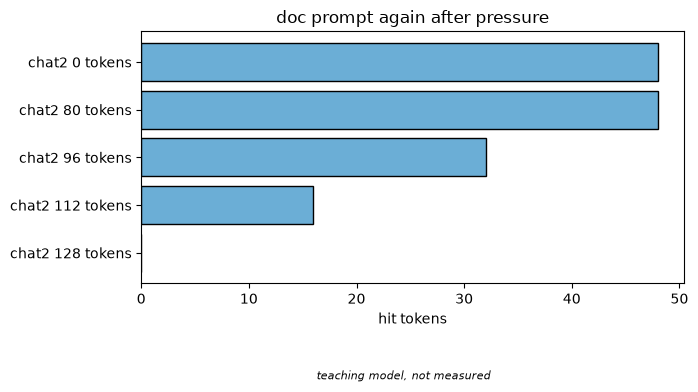

In [11]:
view.bar_chart({f"chat2 {row['chat2_tokens']} tokens": row["hit_tokens"] for row in pressure},
               unit="hit tokens", note="teaching model, not measured",
               title="doc prompt again after pressure")

**왜 이렇게 설계했나.** 코드 주석은 앞쪽 재사용을 GPU locality를 위한 LIFO로, 뒤쪽 재사용을 LRU 동작을 위한 FIFO로 적습니다(P2-10). 역순 반납의 이유도 적혀 있습니다. 꼬리 block이 먼저 쫓겨나게 하려는 것입니다(P2-11). 문서의 이유는 꼬리 block이 재사용될 가능성이 낮다는 것입니다. hash 사슬은 처음 없는 곳에서 끊기므로(3절) 앞쪽을 남기는 편이 맞습니다. 이 마지막 연결은 수업의 해석입니다. 직접 만든 리스트를 쓰는 이유는 PR #9972가 적습니다. `.remove()`가 O(1)이고 Python 객체를 새로 만들지 않습니다. 같은 PR의 표를 읽을 때는 주의가 필요합니다. offline batch에서 입력 처리량이 17916.36에서 32258.08 tok/s로 오른 행은 캐시 적중 49%일 때 prefix caching 전체의 효과이고, 기준선은 prefix caching이 없는 main입니다. 캐시를 끈 같은 PR은 17749.25 tok/s로 기준과 거의 같습니다. 연결 리스트만의 속도 이득은 이 표에 없습니다.

## 3. hash 사슬, salt, 적중 상한

block을 같이 쓰려면 "이 block의 KV가 내 프롬프트에도 맞는가"를 판단해야 합니다. KV는 그 위치까지의 token 전체에 달려 있으므로 block 안의 token만 비교해서는 부족합니다. vLLM은 hash에 부모를 넣어 이것을 풉니다.

`hash(부모 block hash, 이 block의 token 튜플, 추가 key)`

첫 block의 부모는 `NONE_HASH`입니다. 이 값은 seed에서 만들어집니다. 환경변수 `PYTHONHASHSEED`가 있으면 그것을 쓰고, 없으면 암호학적 hash(기본 sha256)는 고정 seed를, `xxhash` 계열은 프로세스마다 새 난수 seed를 씁니다([`kv_cache_utils.py:122`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L122), [`kv_cache_utils.py:131`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L131), P2-25). 그래서 hash가 같다는 것은 **처음부터 이 block까지 token과 추가 key가 모두 같다**는 뜻이 됩니다(D-16). 부모가 사슬로 이어지므로 앞 block이 하나라도 다르면 뒤 block의 hash도 전부 다릅니다(P2-45, P2-47).

**공식 문서.** 문서는 같은 구성을 부모 hash, block token, 추가 hash 세 가지로 설명합니다([`prefix_caching.md:5`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/prefix_caching.md#L5), [`prefix_caching.md:15`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/prefix_caching.md#L15)).

**코드.** `hash_block_tokens`([`kv_cache_utils.py:695`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L695))가 한 block의 hash를 만들고, `get_request_block_hasher`([`kv_cache_utils.py:941`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L941))가 요청의 hash 목록을 계산하는 함수를 돌려줍니다. prefix caching을 켜는 `enable_prefix_caching`은 `CacheConfig`의 기본값이 `True`이고([`cache.py:141`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/cache.py#L141), P2-24), `EngineArgs` 쪽 기본은 `None`이라 사용자가 값을 주지 않으면 모델이 지원하는지로 정합니다([`arg_utils.py:3021`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L3021), `vllm serve`와 `LLM` 클래스가 같은 경로입니다). 생성 모델은 attention 없는 모델과 encoder-decoder를 뺀 나머지에서 켜지고, pooling 모델은 조건부이며, RISC-V CPU에서는 꺼집니다([`arg_utils.py:3041`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L3041), [`model.py:2221`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/model.py#L2221)). 알고리즘 기본은 `sha256`입니다([`cache.py:143`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/cache.py#L143)). `--prefix-caching-hash-algo`로 바꿉니다([`arg_utils.py:1377`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L1377), P2-27).

hash는 `hash_block_size` 단위로 계산해 이어 붙이고, group의 block이 더 크면 이 hash를 묶어 재사용합니다(P2-26). 기본 설정은 두 크기가 같으므로 시뮬레이터도 같게 둡니다.

**salt.** `cache_salt`는 시작 위치가 0인 block의 추가 key에만 들어갑니다([`kv_cache_utils.py:647`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L647), P2-28). 한 곳에만 넣어도 부모 사슬을 타고 뒤 block 전체로 퍼집니다. 문서는 이것을 다중 사용자 환경의 격리 수단으로 설명합니다([`prefix_caching.md:87`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/prefix_caching.md#L87)). 길이 제한은 코드 안에서 둘로 갈립니다. 필드 정의는 1024자([`protocol.py:488`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/protocol.py#L488))인데 실제 검증기는 128자 초과를 거부합니다([`protocol.py:39`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/generate/base/protocol.py#L39), P5-10). 128자 이하로 쓰고 금지 문자 `@`, `/`, 역슬래시, NUL을 피하세요.

**직접 관찰.** `doc` 프롬프트의 hash 세 개를 네 조건으로 계산합니다. 시뮬레이터의 hash 값은 vLLM과 다르고 구조만 같습니다.

In [12]:
changed_at_20 = list(DOC_PROMPT)
changed_at_20[19] = 9999  # 20번째 token만 다르다
columns = {"no_salt": request_block_hashes(DOC_PROMPT),
           "salt_a": request_block_hashes(DOC_PROMPT, cache_salt="tenant-a"),
           "salt_b": request_block_hashes(DOC_PROMPT, cache_salt="tenant-b"),
           "token_20_changed": request_block_hashes(changed_at_20)}
view.table([{"block": i, "tokens": f"{i * 16}..{i * 16 + 15}", **{k: v[i] for k, v in columns.items()}}
            for i in range(3)])

,block,tokens,no_salt,salt_a,salt_b,token_20_changed
0,0,0..15,f0882bf4e8d5,e708b4124086,75378be9a4fd,f0882bf4e8d5
1,1,16..31,a20732605fb0,93a9980617fe,0c8cc81bc18c,aaed6e3b1e87
2,2,32..47,5d224dbf811f,d69a9e15c9d9,2f5d486aead0,aca324c472b3


**관찰할 것.** `no_salt`와 `token_20_changed`를 행별로 비교해 어느 행부터 값이 갈라지는지 찾으세요. `salt_a`와 `salt_b`는 첫 행부터 어떻습니까? 54 token인데 왜 행이 3개뿐인지도 적으세요.

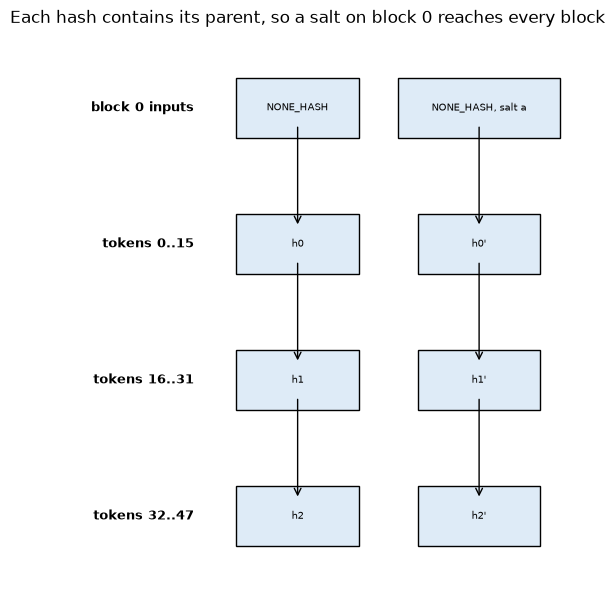

In [13]:
view.lane_diagram(
    {"block 0 inputs": ["NONE_HASH", "NONE_HASH, salt a"], "tokens 0..15": ["h0", "h0'"],
     "tokens 16..31": ["h1", "h1'"], "tokens 32..47": ["h2", "h2'"]},
    [("NONE_HASH", "h0", ""), ("h0", "h1", ""), ("h1", "h2", ""),
     ("NONE_HASH, salt a", "h0'", ""), ("h0'", "h1'", ""), ("h1'", "h2'", "")],
    title="Each hash contains its parent, so a salt on block 0 reaches every block")

**꽉 찬 block만 hash를 얻습니다.** 문서가 한 줄로 적고([`prefix_caching.md:22`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/prefix_caching.md#L22)), 코드는 기본 설정에서 부분 tail 등록을 건너뜁니다([`single_type_kv_cache_manager.py:845`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/single_type_kv_cache_manager.py#L845), P2-43). 그래서 앞 턴 끝(생성한 token 포함)의 꽉 차지 않은 마지막 block은 공유되지 않고, 다음 턴이 그 1~15 token을 다시 계산합니다(P5-05). "최대 15"는 이 경우와 기본 block 크기 16에 한한 값입니다. 같은 프롬프트를 다시 보낼 때 길이가 block의 배수면 아래 조회 상한 때문에 block 하나 16 token이 통째로 다시 계산됩니다(P5-06). 16과 hash 크기가 다른 hybrid 모델(GLM의 main block은 4352)의 값은 확인하지 않았습니다. 예외가 하나 있습니다. cache block이 hash 단위보다 큰 hybrid 구성에서는 `FullAttentionManager`가 prompt의 마지막 경계를 부분 항목으로 등록할 수 있습니다(P2-44).

**등록 시점은 `allocate_slots` 안입니다.** 계산이 끝날 token까지, 다만 `request.num_tokens`를 넘지 않게 올립니다([`kv_cache_manager.py:607`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_manager.py#L607), [`block_pool.py:226`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/block_pool.py#L226), P2-42). 이 한계 때문에 두 결과가 나옵니다. 생성한 답변 token의 꽉 찬 block도 다음 턴에 재사용됩니다. 그리고 아직 검증되지 않은 draft token은 hash에 들어가지 않습니다(P2-53, 5절).

**조회 상한은 `request.num_tokens - 1`입니다.** 전부 적중해도 마지막 token의 logits는 얻어야 하니 그 token은 다시 계산합니다([`kv_cache_manager.py:295`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_manager.py#L295), [`kv_cache_manager.py:264`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_manager.py#L264), P2-29, P2-30, P5-06). 적중은 block 단위라서 상한이 block 경계 바로 아래에 걸리면 block 하나가 통째로 다시 계산됩니다.

**먼저 예측하세요.** 고정 예제 E2입니다. `doc`(54 token)을 끝낸 뒤 다음 네 요청을 각각 보냅니다. (1) 같은 프롬프트, (2) 그 프롬프트의 앞 48 token만, (3) 20번째 token만 다른 프롬프트, (4) 같은 프롬프트에 salt를 붙인 요청. 네 경우의 `hit_tokens`와 다시 계산할 token 수를 표로 적으세요. 특히 (2)는 상한을 계산한 뒤 block 단위로 내려야 합니다.

In [14]:
def repeat_hit(case, tokens, salt=None, first_salt=None):
    """doc을 끝내고 반납한 뒤 tokens를 다시 보낸다. 매번 새 pool에서 시작한다."""
    mgr = KVManagerSim(12)
    first = mgr.add_request("doc", DOC_PROMPT, cache_salt=first_salt)
    mgr.schedule(first)
    mgr.free(first)
    result = mgr.schedule(mgr.add_request("again", tokens, cache_salt=salt))
    return {"case": case, "prompt_tokens": len(tokens), "max_hit_tokens": len(tokens) - 1,
            "hit_tokens": result.hit_tokens, "hit_block_ids": result.hit_block_ids,
            "recompute_tokens": result.num_scheduled_tokens}


view.table([repeat_hit("same prompt", DOC_PROMPT),
            repeat_hit("first 48 tokens", DOC_PROMPT[:48]),
            repeat_hit("token 20 changed", changed_at_20),
            repeat_hit("salt added", DOC_PROMPT, salt="tenant-a")])

,case,prompt_tokens,max_hit_tokens,hit_tokens,hit_block_ids,recompute_tokens
0,same prompt,54,53,48,"[1, 2, 3]",6
1,first 48 tokens,48,47,32,"[1, 2]",16
2,token 20 changed,54,53,16,[1],38
3,salt added,54,53,0,[],54


**관찰할 것.** `max_hit_tokens`와 `hit_tokens`를 나란히 읽으세요. 첫 행과 둘째 행에서 `recompute_tokens`가 왜 프롬프트가 짧은 쪽에서 더 큽니까? 셋째 행의 `hit_block_ids` 길이와 위 hash 표에서 갈라진 행을 연결하세요.

### 실제 클래스와 맞춰 본 결과

`data/reference_kv.json`은 v0.32.0 소스의 실제 `KVCacheManager`에 같은 입력을 넣은 기록입니다(`docs/REFERENCE_RUN.md`). 범위가 좁습니다. 단일 full-attention group, `block_size=16`, sha256, CPU에서 관리 클래스만 돌렸습니다. GPU 서버나 수업 Pod가 이렇게 동작한다는 뜻이 아니고, hash 값 자체는 비교하지 않았습니다. 그 범위 안에서 `status`가 `ran`이고 `match`가 `True`인 시나리오만 "실제 클래스와 같은 결과"라고 말할 수 있습니다. E2의 세 경우에 가까운 시나리오가 있습니다. 같은 프롬프트는 `prefix_hit_repeat`와 같고, `hit_cap_num_tokens_minus_1`은 48 token 요청을 두 번 보낸 구성이며(위 표는 54 token 뒤 48 token입니다), `different_salt`는 두 요청의 salt가 서로 다른 구성입니다(위 표는 salt 없음 뒤 salt 있음입니다). 적중 수는 같지만 입력이 같지는 않은 것입니다. 20번째 token이 다른 경우, E3의 구성 그대로의 반납 순서, 4절의 preempt, 5절의 draft, 6절의 hybrid는 이 시나리오에 없으므로 시뮬레이터 결과일 뿐입니다.

In [15]:
import json

reference_table = view.table(reference_rows(), ["name", "status", "match"])
display(reference_table)
reference = json.loads((DATA_DIR / "reference_kv.json").read_text(encoding="utf-8"))
if reference["status"] != "ran":
    print("실제 클래스를 실행하지 못했습니다. 이유:", reference.get("reason"))
else:
    rows = []
    for scenario in reference["scenarios"]:
        for real, sim in zip(scenario["real"], scenario["sim"]):
            if real["op"] == "schedule":
                rows.append({"scenario": scenario["name"], "request": real["request_id"],
                             "real_hit": real["hit_tokens"], "sim_hit": sim["hit_tokens"],
                             "real_new_blocks": real["new_block_ids"], "sim_new_blocks": sim["new_block_ids"],
                             "same_free_queue": real["free_queue"] == sim["free_queue"]})
    display(view.table(rows))

,name,status,match
0,sequential_allocate,ran,True
1,prefix_hit_repeat,ran,True
2,hit_cap_num_tokens_minus_1,ran,True
3,different_salt,ran,True
4,free_then_reuse_order,ran,True
5,eviction_under_pressure,ran,True


,scenario,request,real_hit,sim_hit,real_new_blocks,sim_new_blocks,same_free_queue
0,sequential_allocate,R1,0,0,"[1, 2, 3, 4]","[1, 2, 3, 4]",True
1,sequential_allocate,R2,0,0,"[5, 6]","[5, 6]",True
2,prefix_hit_repeat,R1,0,0,"[1, 2, 3, 4]","[1, 2, 3, 4]",True
3,prefix_hit_repeat,R2,48,48,[4],[4],True
4,hit_cap_num_tokens_minus_1,R1,0,0,"[1, 2, 3]","[1, 2, 3]",True
5,hit_cap_num_tokens_minus_1,R2,32,32,[4],[4],True
6,different_salt,R1,0,0,"[1, 2, 3, 4]","[1, 2, 3, 4]",True
7,different_salt,R2,0,0,"[4, 5, 6, 7]","[4, 5, 6, 7]",True
8,free_then_reuse_order,R1,0,0,"[1, 2, 3, 4]","[1, 2, 3, 4]",True
9,free_then_reuse_order,R2,0,0,[4],[4],True


**왜 이렇게 설계했나.** 상한의 이유는 코드 주석에 그대로 있습니다([`kv_cache_manager.py:289`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_manager.py#L289)). 마지막 token은 logits 때문에 다시 계산해야 하고, `allocate_slots`가 `num_computed_tokens`의 block 정렬을 요구해서 block 전체가 다시 계산될 수 있으며, 주석은 이 제약을 없애면 성능이 조금 나아질 수 있다고 덧붙입니다. 기본으로 켠 배경은 V1 구조를 정리한 이슈 #8779가 prefix caching을 첫째가는 기능으로 꼽은 데서 볼 수 있습니다. 다만 그 본문에 효과 수치는 없습니다. 부모를 hash에 넣는 대가는 Part 5에서 다룹니다.

## 4. preempt와 recompute

schedule은 running 요청을 먼저 훑습니다. 어떤 요청에 줄 block이 모자라면 `allocate_slots`가 `None`을 돌려줍니다([`kv_cache_manager.py:577`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_manager.py#L577), P2-32). 그러면 scheduler는 누군가를 내보내고 다시 시도하며, 할당이 될 때까지 되풀이합니다([`scheduler.py:778`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L778), P2-34). 단 connector가 반납을 기다리는 block을 쥐고 있거나 희생자의 block을 바로 풀 수 없으면 내보내지 않고 이번 step을 멈춥니다([`scheduler.py:788`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L788)). 이 예외는 코드 읽기이고 여기서 모델링하지 않습니다.

| 단계 | 내용 | 코드 |
|---|---|---|
| 희생자 선택 | PRIORITY는 `(priority, arrival_time)`이 최대인 요청, FCFS는 `running[-1]` | [`scheduler.py:797`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L797), [`scheduler.py:802`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L802) |
| 자기 자신이면 | 자기도 똑같이 내보낸 뒤(block 반납, waiting 맨 앞) 더 내보낼 요청이 없으므로 running 순회를 멈춘다 | [`scheduler.py:842`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L842) |
| 내보내기 | block 전부 반납, `num_computed_tokens = 0`, draft 비움, 상태 PREEMPTED, waiting 맨 앞 | [`scheduler.py:1571`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L1571), [`scheduler.py:1593`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L1593), [`scheduler.py:1613`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L1613) |
| 그 step의 waiting | preempt가 있었으면 waiting을 보지 않는다 | [`scheduler.py:899`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L899) |
| 복귀 | `num_computed_tokens == 0`이므로 prefix cache를 조회한다 | [`scheduler.py:959`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L959) |

근거는 P2-34, P2-35, P2-36, P2-37, P3-23, D-07입니다.

**실제 클래스 실행.** `data/reference_sched.json`은 v0.32.0의 실제 `Scheduler`를 CPU에서 돌려 `sched_sim`과 행을 비교한 기록입니다(범위: 단일 full-attention group, block 16, 서버 아님). 위 표 가운데 세 행이 여기서 확인됩니다. FCFS 희생자는 `running[-1]`이고(`preempt_tail_by_head`), 자기 자신이면 자기를 내보낸 뒤 순회를 멈추며(`self_preempt_tail`, `self_preempt_after_other`, 이 step의 동작은 prefix cache와 전체 입력 검사를 켜고 끈 네 조합 모두 같고, `prefix=on`의 복귀 step은 sim과 token 수가 다르며 그 차이가 아래의 적중입니다), 복귀 때 prefix cache를 조회해 `prefix=on`에서 실제로 적중이 났습니다(`self_preempt_tail`, `comeback_faq`). preempt가 있었던 step에서 waiting을 보지 않는 행은 이 실행으로 구별되지 않습니다. `waiting_skipped_then_head_blocks`의 행은 같지만, 그 step에는 맨 앞의 `B`가 block이 모자라 이 규칙이 없어도 `C`가 막히기 때문입니다. 이 행과 PRIORITY 정책, connector 예외, speculative decoding은 코드 읽기로 남습니다.

**공식 문서.** 문서는 V1의 기본 preemption 방식이 `SWAP`이 아니라 `RECOMPUTE`이고, 이 구조에서 재계산의 부담이 더 적다고 적습니다([`optimization.md:47`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/configuration/optimization.md#L47)).

**직접 관찰.** pool은 usable block 11개입니다. `chat` 34, `doc` 54, `faq` 20 token이 차례로 들어와 9개를 쓰고, `doc`이 생성을 이어 갑니다. 아래 함수의 루프가 scheduler의 재시도를 흉내 냅니다. waiting 큐와 예산은 이 모듈에 없고 `sched_sim`(`03`)의 몫입니다.

In [16]:
# 실패 재현: block이 모자라면 schedule이 None을 돌려주고 running의 마지막 요청이 밀려난다
def run_pressure(num_blocks=12, doc_target=104):
    """doc을 한 token씩 키운다. None이면 running[-1]을 preempt하고 다시 시도한다."""
    mgr = KVManagerSim(num_blocks)
    chat = mgr.add_request("chat", CHAT_PROMPT)
    doc = mgr.add_request("doc", DOC_PROMPT)
    faq = mgr.add_request("faq", FAQ_PROMPT)
    for request in (chat, doc, faq):
        mgr.schedule(request)
    running, rows = [chat, doc, faq], []
    while doc.num_tokens < doc_target:
        mgr.append_output(doc, [9000 + doc.num_tokens])
        free_before = mgr.free_queue_ids()
        result = mgr.schedule(doc, 1)
        while result is None:
            victim = running[-1]
            if victim is doc:  # 자기 자신이면 자기도 내보내고 그 step을 끝낸다
                running.pop()
                mgr.preempt(doc)
                rows.append({"doc_tokens": doc.num_tokens, "schedule": "None", "free_before": free_before,
                             "victim": "doc itself: preempted, step ends"})
                return mgr, doc, faq, rows
            running.pop()
            out = mgr.preempt(victim)
            rows.append({"doc_tokens": doc.num_tokens, "schedule": "None", "free_before": free_before,
                         "victim": victim.request_id, "freed_block_ids": out["freed_block_ids"],
                         "free_after": mgr.free_queue_ids()})
            result = mgr.schedule(doc, 1)
    return mgr, doc, faq, rows


mgr, doc, faq, rows = run_pressure()
print("틀린 기대: doc은 block이 늘 있다고 가정하고 104 token까지 간다")
print("실제 값  :", len(rows), "번 None을 받았고 faq 상태는", faq.status, ", preempt 횟수", faq.num_preemptions)
display(view.table(rows))
view.table([{"request": r.request_id, "status": r.status, "num_computed_tokens": r.num_computed_tokens,
             "block_table": mgr.block_table(r)} for r in mgr.requests.values()])

틀린 기대: doc은 block이 늘 있다고 가정하고 104 token까지 간다
실제 값  : 1 번 None을 받았고 faq 상태는 PREEMPTED , preempt 횟수 1


,doc_tokens,schedule,free_before,victim,freed_block_ids,free_after
0,97,None,[],faq,"[9, 8]","[9, 8]"


,request,status,num_computed_tokens,block_table
0,chat,RUNNING,34,"[1, 2, 3]"
1,doc,RUNNING,104,"[4, 5, 6, 7, 10, 11, 9]"
2,faq,PREEMPTED,0,[]


**관찰할 것.** `free_before`가 비어 있는 시점의 `doc_tokens`가 block 경계와 어떤 관계인지 계산하세요. `freed_block_ids`의 순서를 2절의 규칙으로 설명하고, 아래 표에서 `faq`의 `num_computed_tokens`와 `block_table`을 읽으세요.

`faq`는 나중에 돌아옵니다. 이때 전부 다시 계산할까요? 다음 셀은 `doc`이 멈추는 길이만 104와 114로 바꿉니다. 둘 다 `doc`이 끝난 뒤 `faq`가 돌아옵니다. 복귀 때의 watermark는 모델링하지 않았습니다.

In [17]:
def comeback(num_blocks=12, doc_target=104):
    mgr, doc, faq, rows = run_pressure(num_blocks, doc_target)
    mgr.free(doc)
    row = {"num_blocks": num_blocks, "doc_target": doc_target, "faq_status": faq.status,
           "faq_preemptions": faq.num_preemptions}
    if faq.status == "PREEMPTED":
        result = mgr.schedule(faq)
        row |= {"hit_tokens": result.hit_tokens, "hit_block_ids": result.hit_block_ids,
                "recompute_tokens": result.num_scheduled_tokens}
    return row


view.table([comeback(doc_target=104), comeback(doc_target=114)])

,num_blocks,doc_target,faq_status,faq_preemptions,hit_tokens,hit_block_ids,recompute_tokens
0,12,104,PREEMPTED,1,16,[8],4
1,12,114,PREEMPTED,1,0,[],20


위 표의 두 행은 `faq` 20 token 전부를 다시 계산하는 것이 항상 일어나는 일이 아니라 최악의 경우임을 보여 줍니다. prefix caching이 켜져 있고 반납한 hash block이 아직 덮어써지지 않았을 때 돌아오면 적중으로 건집니다(P2-37, P3-23). 이 표는 시뮬레이터 결과이며 실제 scheduler를 돌린 것이 아닙니다. 같은 현상을 실제 `Scheduler`에서 본 것은 `reference_sched.json`의 `comeback_faq`입니다. 입력이 달라 이 표의 값을 확인한 것은 아니고, 복귀 때 조회가 적중으로 이어진다는 점만 확인됩니다.

**왜 이렇게 설계했나.** 문서는 V1에서 재계산이 swap보다 부담이 적다고 밝힙니다. 다만 그 판단의 근거가 된 PR은 소스와 공식 문서에서 찾지 못했으므로 문서의 문장까지만 말할 수 있습니다. 재계산의 실제 비용은 `03`의 주제입니다.

## 5. speculative decoding과 MTP

서버 구성 레시피의 값은 `{"method":"mtp","num_speculative_tokens":5}`입니다(R-02). 같은 레시피의 GB200 TP4 예시는 `--kv-cache-dtype fp8`도 쓰지만 수업 자료의 README에는 KV dtype이 없고, 레시피는 Hopper를 BF16 KV로 돌려야 한다고 따로 적습니다. 그래서 이 노트북은 KV dtype을 가정한 용량 숫자를 쓰지 않습니다. 수업 Pod는 v0.28.1rc1 dev 빌드로 적혀 있고(R-01) 아래 경로는 v0.32.0 코드 기준이므로, 이 절은 "수업 서버가 이렇게 동작한다"가 아니라 "v0.32.0 코드가 이렇게 적혀 있다"로 읽으세요.

speculative decoding은 target model이 한 step에 한 token씩 뽑는 대신, drafter가 K개를 먼저 제안하고 target이 그것을 한 번에 검증하는 방식입니다. 이 한 문장은 일반 설명이고, 이어지는 내용부터 근거를 답니다. 방식 이름은 문서가 나열합니다(`method` 값, [`README.md:85`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/speculative_decoding/README.md#L85), D-31). 수업 구성의 `mtp`(Multi-Token Prediction)는 별도 draft model 없이 target model이 가진 다중 token 예측 능력으로 draft를 내는 방식입니다([`mtp.md:3`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/speculative_decoding/mtp.md#L3), D-31). KV 처리는 공식 문서에 설명이 없어서 아래는 모두 코드 근거입니다.

| 순서 | 무슨 일 | 코드 |
|---|---|---|
| 1 | draft token은 `Request.spec_token_ids`에 붙고 `num_tokens_with_spec`에 포함된다 | [`request.py:183`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/request.py#L183), [`request.py:299`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/request.py#L299) |
| 2 | scheduler는 계산 수가 이 길이를 따라잡도록 token을 준다. prefill과 decode를 맞추던 틀 그대로다 | [`scheduler.py:594`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L594) |
| 3 | `allocate_slots`가 `num_lookahead_tokens`만큼 칸을 더 잡는다 | [`kv_cache_manager.py:542`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_manager.py#L542), [`scheduler.py:781`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L781) |
| 4 | worker로 넘기는 draft는 `scheduled_spec_decode_tokens`에 실린다. 줄 자리가 부족하면 뒷부분을 버린다 | [`scheduler.py:860`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L860), [`output.py:251`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/output.py#L251) |
| 5 | 틀린 수 `num_rejected`만큼 `num_computed_tokens`를 되돌린다. 값은 지우지 않는다 | [`scheduler.py:2126`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L2126) |

근거는 P2-03, P2-33, P2-49, P2-50, P2-51, P2-52입니다. draft token이 prefix cache에 들어가지 않는 것은 3절에서 본 상한 때문입니다(P2-53, [`kv_cache_manager.py:454`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_manager.py#L454)).

### `num_lookahead_tokens`와 추가 slot

이름이 비슷한 값이 둘 있어 자주 헷갈립니다. `num_lookahead_tokens`는 **KV 칸**을 target의 계산 범위 너머로 얼마나 더 잡을지입니다. `VllmConfig`의 property 한 곳에서 정하고 scheduler와 warmup이 함께 읽습니다([`vllm.py:614`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/vllm.py#L614), [`scheduler.py:289`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L289), P2-54). running 요청의 `allocate_slots`는 이 값을 그대로 넘기고, waiting 요청은 KV를 비동기로 받아 오는 중이면 0으로 낮춥니다([`scheduler.py:1224`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L1224), [`scheduler.py:1261`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L1261)). `mtp`는 `use_eagle`에 포함됩니다([`speculative.py:1944`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/speculative.py#L1944)). `max_num_new_slots_for_drafting`은 **입력 한도**(`input_budget`)에서 요청마다 먼저 빼는 자리입니다. `token_budget`에서는 실제 계산할 `num_new_tokens`만 뺍니다([`speculative.py:1887`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/speculative.py#L1887), [`scheduler.py:613`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L613), P2-57).

| 방식 | `num_lookahead_tokens` | 추가 slot | K=5일 때 |
|---|---|---|---|
| `mtp`, `eagle3` | K | 0 | 5칸 / 0 |
| draft model | K | 1 | 5칸 / 1 |
| `dflash` | K+1 | K | 6칸 / 5 |
| n-gram 또는 speculative 없음 | 0 | 0 | 0칸 / 0 |

docstring 표에는 P-EAGLE(K-1), DSpark(K-1), PARD(K)도 있고, DSpark는 anchor 방식이면 lookahead가 K, 채워 넣는 방식이면 K+1입니다. PR #59468은 DFlash와 DSpark의 추가 slot을 0으로 바꿨지만 v0.32.0에는 없습니다. 이 값은 코드 읽기입니다.

drafter 쪽 KV 위치도 같은 pool 아래에 있습니다. 모델의 layer를 모아 spec을 만드는 함수가 draft layer까지 모으고, draft prefill은 target의 attention metadata를 재사용합니다([`attn_utils.py:139`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/attn_utils.py#L139), P2-56). MTP 층이 KV를 어떻게 공유하는지는 이 노트북이 다루지 않습니다. GLM에서 MTP 층이 항상 MLA 층(K와 V 대신 잠재 벡터 하나를 저장하는 attention, 아래 GLM 절과 `02c`)이라는 데까지만 확인됩니다([`model.py:370`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/glm5next/common/model.py#L370)).

**직접 관찰.** 고정 예제 E4입니다. 2절과 같은 `doc`, 전체 62, 계산 61에서 시작합니다. `K=5`입니다. 이번 step은 마지막으로 뽑은 token 하나와 draft 5개, 합 6 token을 계산하고, lookahead 5를 더해 `61 + 6 + 5 = 72`칸이 필요하니 block은 5개가 됩니다. 시뮬레이터는 target이 draft 위치를 계산할 때의 slot 쓰기만 표지로 남깁니다. drafter 자체의 쓰기와 draft가 맞았는지의 판정은 모델링하지 않았고, `verify_drafts`는 뽑힌 token 수로만 승인 수를 셉니다.

In [18]:
K = 5


def e4_schedule():
    """E4 출발 상태에서 draft를 붙여 한 step을 스케줄한다."""
    mgr, chat, doc = e3_state()
    drafts = toks(7000, K)
    mgr.set_draft_tokens(doc, drafts)
    before = {"num_tokens": doc.num_tokens, "num_tokens_with_spec": doc.num_tokens_with_spec,
              "num_computed_tokens": doc.num_computed_tokens, "block_table": mgr.block_table(doc)}
    result = mgr.schedule(doc, num_lookahead_tokens=K)
    after = {"num_tokens": doc.num_tokens, "num_tokens_with_spec": doc.num_tokens_with_spec,
             "num_computed_tokens": doc.num_computed_tokens, "block_table": result.block_table}
    return {"mgr": mgr, "doc": doc, "drafts": drafts, "rows": [{"when": "before", **before}, {"when": "after", **after}],
            "new_block_ids": result.new_block_ids, "scheduled": result.num_scheduled_tokens}


e4 = e4_schedule()
print("이번 step 계산:", e4["scheduled"], "token / 새 block:", e4["new_block_ids"],
      "/ hash가 있는 block:", e4["mgr"].cached_block_ids())
view.table(e4["rows"])

이번 step 계산: 6 token / 새 block: [8] / hash가 있는 block: [1, 2, 4, 5, 6]


,when,num_tokens,num_tokens_with_spec,num_computed_tokens,block_table
0,before,62,67,61,"[4, 5, 6, 7]"
1,after,62,67,67,"[4, 5, 6, 7, 8]"


**먼저 예측하세요.** 검증 결과 뽑힌 token이 3개입니다. 1개는 target이 새로 뽑은 token이고 나머지가 받아들인 draft입니다. 받아들인 draft 수, 거부한 수, 검증 뒤의 `num_computed_tokens`, `num_tokens`를 계산하세요. block table은 바뀔까요? 숫자를 적은 뒤 실행하세요.

In [19]:
NUM_GENERATED = 3


def marks(state, positions):
    """position의 slot에 남은 표지. KV 값이 아니다."""
    table = state["mgr"].block_table(state["doc"])
    return {p: state["mgr"].slot_contents(slot_id(table, p)) for p in positions}


def e4_verify(state, num_generated):
    mgr, doc, drafts = state["mgr"], state["doc"], state["drafts"]
    state["marks_after_draft"] = marks(state, range(61, 67))
    # 앞 num_generated-1개는 draft와 같고 마지막 하나는 target이 새로 뽑은 token이라고 둔다
    generated = drafts[:num_generated - 1] + [8888]
    state["verified"] = mgr.verify_drafts(doc, generated)
    return state


e4 = e4_verify(e4_schedule(), NUM_GENERATED)
view.table([e4["verified"]])

,num_drafts,num_accepted,num_rejected,num_computed_tokens,num_tokens,block_table
0,5,2,3,64,65,"[4, 5, 6, 7, 8]"


**관찰할 것.** `num_computed_tokens`, `num_tokens`, `block_table` 세 칸을 앞 표의 `after` 행과 비교해, 무엇이 줄고 무엇이 늘고 무엇이 그대로인지 적으세요. 코드의 식은 `num_accepted`([`scheduler.py:2118`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L2118)), `num_rejected`([`scheduler.py:2119`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L2119)), `num_computed_tokens`([`scheduler.py:2126`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L2126)) 세 줄입니다.

In [20]:
def e4_next(state):
    """되감은 위치부터 한 token을 계산하는 다음 step."""
    mgr, doc = state["mgr"], state["doc"]
    span = range(61, 68)
    state["marks_after_verify"] = marks(state, span)
    state["next_position"] = doc.num_computed_tokens
    state["cached_before_next"] = mgr.cached_block_ids()
    first_event = len(mgr.events)
    mgr.schedule(doc, 1)
    state["overwrites"] = [e for e in mgr.events[first_event:] if e["kind"] == "overwrite"]
    state["marks_after_next"] = marks(state, span)
    state["cached_after_next"] = mgr.cached_block_ids()
    return state


def show_mark(mark):
    if mark is None:
        return "-"
    return f"{mark['token_id']}" + (" draft" if mark["is_draft"] else "")


def slot_rows(state):
    table = state["mgr"].block_table(state["doc"])
    return view.table([{"position": p, "slot": slot_id(table, p),
                        "after_draft_step": show_mark(state["marks_after_draft"].get(p)),
                        "after_verify": show_mark(state["marks_after_verify"][p]),
                        "after_next_step": show_mark(state["marks_after_next"][p])}
                       for p in range(61, 68)])


e4 = e4_next(e4)
print("다음 step의 position:", e4["next_position"], "/ num_computed_tokens:", e4["doc"].num_computed_tokens,
      "/ block_table:", e4["mgr"].block_table(e4["doc"]))
print("hash가 있는 block:", e4["cached_before_next"], "->", e4["cached_after_next"])
slot_rows(e4)

다음 step의 position: 64 / num_computed_tokens: 65 / block_table: [4, 5, 6, 7, 8]
hash가 있는 block: [1, 2, 4, 5, 6] -> [1, 2, 4, 5, 6, 7]


,position,slot,after_draft_step,after_verify,after_next_step
0,61,125,2007,2007,2007
1,62,126,7000 draft,7000,7000
2,63,127,7001 draft,7001,7001
3,64,128,7002 draft,7002 draft,8888
4,65,129,7003 draft,7003 draft,7003 draft
5,66,130,7004 draft,7004 draft,7004 draft
6,67,131,-,-,-


표의 칸은 KV 값이 아니라 어느 token을 계산해 썼는지 남긴 표지입니다. `draft`가 붙은 칸은 확정되지 않은 token의 자리입니다. 다음 표와 그림은 같은 일을 event와 position 축으로 다시 보여 줍니다.

**관찰할 것.** `after_verify`와 `after_next_step` 칸을 position별로 비교해 값이 바뀐 행이 어디인지 찾고, 그 행의 `slot`을 slot 식으로 직접 계산하세요. 끝까지 `draft`로 남는 행도 찾으세요. 위 출력의 hash 목록에 새로 들어온 block은 몇 번이고, 왜 draft step에서는 들어오지 않았는지 적으세요.

In [21]:
import pandas as pd
with pd.option_context("display.max_colwidth", None):
    display(view.trace_table([e for e in e4["mgr"].events if e["kind"] in ("rollback", "overwrite")]))

,step,actor,kind,request_id,detail
0,5,KVManagerSim,rollback,doc,"{""num_drafts"": 5, ""num_accepted"": 2, ""num_rejected"": 3, ""num_computed_before"": 67, ""num_computed_after"": 64}"
1,6,KVManagerSim,overwrite,doc,"{""slot"": 128, ""old"": {""request_id"": ""doc"", ""position"": 64, ""token_id"": 7002, ""is_draft"": true}, ""new"": {""request_id"": ""doc"", ""position"": 64, ""token_id"": 8888, ""is_draft"": false}}"


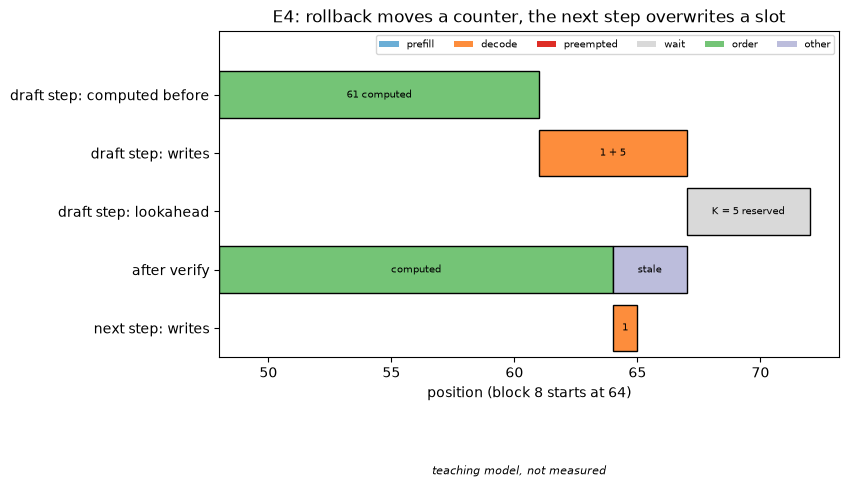

In [22]:
next_position = e4["next_position"]
figure = view.timeline(
    [{"lane": "draft step: computed before", "start": 48, "end": 61, "label": "61 computed", "kind": "order"},
     {"lane": "draft step: writes", "start": 61, "end": 67, "label": "1 + 5", "kind": "decode"},
     {"lane": "draft step: lookahead", "start": 67, "end": 72, "label": "K = 5 reserved", "kind": "wait"},
     {"lane": "after verify", "start": 48, "end": next_position, "label": "computed", "kind": "order"},
     {"lane": "after verify", "start": next_position, "end": 67, "label": "stale", "kind": "other"},
     {"lane": "next step: writes", "start": next_position, "end": next_position + 1, "label": "1", "kind": "decode"}],
    title="E4: rollback moves a counter, the next step overwrites a slot", x_label="position (block 8 starts at 64)")
figure.subplots_adjust(bottom=0.24)  # note가 x축 이름과 겹치지 않게 한다
figure.axes[0].set_ylim(4.5, -1.1)  # 범례가 첫 줄의 막대를 가리지 않게 위쪽 자리를 만든다
figure

되감기의 실체는 정수 하나를 줄이는 일입니다. block을 돌려주지 않고, slot을 지우지 않습니다. 끝까지 `draft`로 남은 자리는 어떻게 될까요. 읽기는 `seq_lens`까지만 보고 `seq_lens`는 `num_computed_tokens`에 이번 step의 token 수를 더한 값이므로(P2-19), 범위 밖의 옛 값을 읽을 경로가 없습니다. 계산이 진행되면 그 자리도 덮어쓰입니다. 이 연결은 수업의 해석입니다.

되감기에는 조건이 하나 있습니다. preempt로 이미 무효가 된 결과는 거부 수를 적용하지 않습니다([`scheduler.py:2124`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L2124), P2-51). 이미 0으로 되돌린 계산 수를 또 줄이면 안 되기 때문입니다. async scheduling에서는 `num_output_placeholders`도 함께 되돌립니다. 시뮬레이터에는 async가 없습니다.

**왜 이렇게 설계했나.** 틀린 KV를 지우지 않는 이유는 코드 주석이 두 가지로 적습니다([`speculator.py:204`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/spec_decode/target_dependent_ar/speculator.py#L204), P2-52). 몇 token이 거부됐는지 CPU가 모르는 채로 CPU-GPU 동기화를 피하려는 것이고, target의 `query_start_loc`과 `seq_lens`를 그대로 재사용하려는 것입니다. 이 주석은 EAGLE 계열 speculator에 있고 MTP는 `use_eagle`에 포함됩니다(P2-54). 자리를 미리 잡아야 하는 이유는 버그 사례가 보여 줍니다. PR #42971은 새 요청의 첫 step에 lookahead block이 없어서 DFlash drafter의 KV가 마지막 prefill block에 기록되고, 그 block이 prefix로 공유돼 오염된 사례입니다. PR #43733은 scheduler 쪽 조건을 고쳤습니다. 예산에서 빼는 draft 자리는 PR #59468이 DFlash와 DSpark에 대해 0으로 바꿨고 v0.32.0에는 아직 없습니다.

## 6. hybrid KV와 GLM-5.3-Flash

지금까지는 모든 층이 같은 규칙을 쓴다고 가정했습니다. 층 종류가 섞이면 무엇이 달라질까요. 필요한 칸 수와 놓아도 되는 칸이 층 종류마다 달라집니다.

**spec과 group.** 층마다 `get_kv_cache_spec()`으로 자기 spec을 밝히고([`attn_utils.py:139`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/attn_utils.py#L139)), 엔진 코어가 모아서([`core.py:268`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L268)) group을 나눕니다([`kv_cache_utils.py:2159`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L2159)). 모든 층의 spec이 같으면 group은 하나입니다(P2-58). slot_mapping도 group마다 하나이므로 같은 group의 층끼리만 공유합니다(P2-17). 문서가 말하는 두 갈래(전부 같으면 한 group, 섞이면 page size를 맞춰 나눔) 사이에 길이 더 있습니다. hybrid manager를 끄면 먼저 spec을 하나로 통일하고, attention이 없는 모델은 빈 목록이며, hisparse, 같은 token 수를 쓰는 다른 spec을 한 group으로 묶는 `UniformTypeKVCacheSpecs`, packed group, hidden-state 층 분리, 실패 시 대체 할당 경로가 있습니다(P2-60, 코드 읽기).

**spec 종류.** `KVCacheSpecKind`는 `full_attention`, `mla_attention`, `sliding_window`, `sliding_window_mla`, `mamba`, `chunked_local_attention`, `sink_full_attention`, `encoder_only_attention`, `cross_attention`, `unknown` 10개입니다([`kv_cache_interface.py:146`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L146), P2-59).

**manager.** 종류마다 manager가 따로 있지만 전부 `SingleTypeKVCacheManager`를 상속합니다([`single_type_kv_cache_manager.py:48`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/single_type_kv_cache_manager.py#L48)). 블로그는 차이를 `get_num_skipped_tokens()`로 설명하고, 아래 표의 값이 그것입니다(P2-65). 코드에서는 `find_longest_cache_hit`도 manager마다 따로 구현돼 있어 이것만이 차이는 아닙니다(P2-68). CrossAttention은 prefix caching 대상이 아닙니다. 아래 다섯 말고도 코드에는 `RSWAManager`, `CircularBufferManager`, `SinkFullAttentionManager`, `HiSparse*Manager`가 있습니다(P2-66).

| manager | 건너뛰는 token | 코드 |
|---|---|---|
| Full | 0 | [`single_type_kv_cache_manager.py:712`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/single_type_kv_cache_manager.py#L712), [`single_type_kv_cache_manager.py:729`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/single_type_kv_cache_manager.py#L729) |
| SlidingWindow | window 앞 구간 | [`single_type_kv_cache_manager.py:1135`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/single_type_kv_cache_manager.py#L1135) |
| ChunkedLocal | 현재 chunk 앞 구간 | [`single_type_kv_cache_manager.py:1368`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/single_type_kv_cache_manager.py#L1368) |
| Mamba | `num_computed_tokens - 1` | [`single_type_kv_cache_manager.py:1954`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/single_type_kv_cache_manager.py#L1954) |
| CrossAttention | prefix caching 대상이 아니다 | [`single_type_kv_cache_manager.py:2115`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/single_type_kv_cache_manager.py#L2115) |

**한 pool.** group마다 메모리를 따로 잡지 않습니다. 같은 byte 영역을 여러 group의 층이 겹쳐 쓰고, block ID 하나를 한 번에 한 group만 소유하므로 충돌하지 않는다고 docstring이 적습니다([`kv_cache_interface.py:1420`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L1420), [`kv_cache_interface.py:1421`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L1421), [`kv_cache_utils.py:1631`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L1631), P2-63). 물리 배치는 block-outer와 layer-outer가 있고 `KVCacheLayout`으로 일반화돼 있습니다. 기본 배치는 backend가 선언한 후보 목록의 첫 값이고, 아무 backend도 선언하지 않으면 layer-outer인 `LBNHC`입니다. 환경변수 `VLLM_KV_CACHE_LAYOUT`과 connector 선호가 먼저 적용됩니다(P2-64, 코드 읽기). 아래 GLM 구성을 실제 함수로 돌린 기록(`reference_specs.json`)에서는 모든 시나리오의 layout이 `BLHNC`였습니다.

크기 맞추기도 필요합니다. `unify_kv_cache_spec_page_size`는 가장 큰 page를 기준으로 맞추고([`kv_cache_utils.py:1292`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L1292), P2-61), 층 수는 같은 종류끼리 병합한 뒤 group 크기를 정하며 최대가 최소의 1.5배 미만이면 최대를 씁니다([`kv_cache_utils.py:1470`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L1470), P2-62). 그래서 padding이 생길 수 있습니다.

**공식 문서.** 문서는 page size를 맞추는 경우들을 설명합니다([`hybrid_kv_cache_manager.md:55`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/hybrid_kv_cache_manager.md#L55)). 맨 위에 초기 단계라 바뀔 수 있다는 경고가 있고([`hybrid_kv_cache_manager.md:4`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/hybrid_kv_cache_manager.md#L4), D-38), 일부 문장은 낡았습니다. 아래 표를 보세요.

**직접 관찰.** 장난감 pool입니다. 층 수나 indexer 압축(kpool, 아래 GLM 절과 `02c`) 같은 값은 들어 있지 않고 block 소유 규칙만 보여 줍니다. 먼저 full group과 sliding window group을 함께 둡니다.

,call,full,swa
0,allocate 20 tokens,"[1, 2]","[3, 4]"
1,allocate 54 tokens,"[5, 6]","[7, 8]"
2,advance to 54 computed (freed ids),[],"[3, 4]"


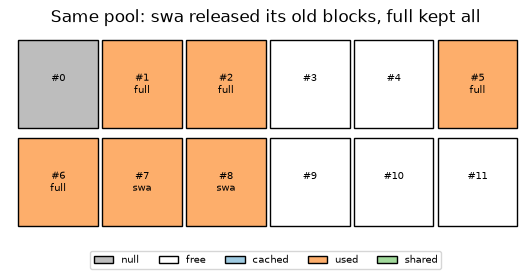

In [23]:
swa_pool = HybridPoolToy(12, [GroupSpec("full", "full"), GroupSpec("swa", "sliding_window", window=16)])
rows = [{"call": "allocate 20 tokens", **swa_pool.allocate("doc", 20)},
        {"call": "allocate 54 tokens", **swa_pool.allocate("doc", 54)},
        {"call": "advance to 54 computed (freed ids)", **swa_pool.advance("doc", 54)}]
display(view.table(rows))
view.block_grid(swa_pool.snapshot(), ncols=6, title="Same pool: swa released its old blocks, full kept all")

,tokens,kda,mla,indexer,tail
0,54,1,4,4,1
1,100,0,3,3,0
2,200,0,6,6,0


,group,toy_kind,block_ids
0,kda,mamba,[1]
1,mla,full,"[2, 3, 4, 5, 11, 12, 13, 17, 18, 19, 20, 21, 22]"
2,indexer,full,"[6, 7, 8, 9, 14, 15, 16, 23, 24, 25, 26, 27, 28]"
3,tail,circular_buffer,[10]


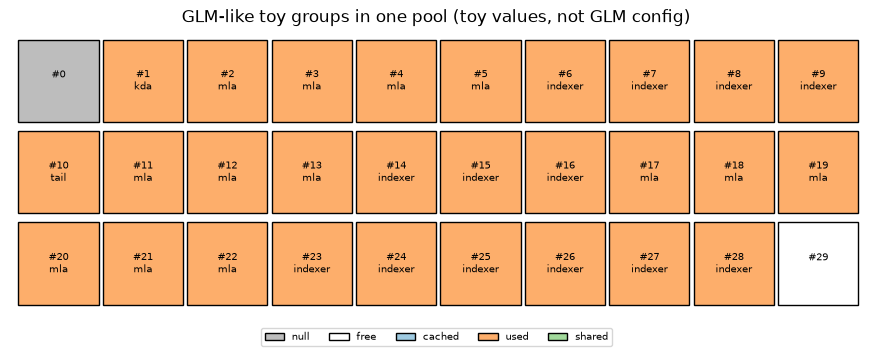

In [24]:
glm_pool = HybridPoolToy(30, glm_like_groups())
rows = []
for tokens in (54, 100, 200):
    new = glm_pool.allocate("doc", tokens)
    rows.append({"tokens": tokens, **{name: len(ids) for name, ids in new.items()}})
display(view.table(rows))
owned = [c["block_id"] for c in glm_pool.snapshot() if c["state"] == "used"]
display(view.table([{"group": g.name, "toy_kind": g.kind,
                     "block_ids": [b for b in owned if glm_pool.owner_of(b) == g.name]}
                    for g in glm_like_groups()]))
view.block_grid(glm_pool.snapshot(), ncols=10, title="GLM-like toy groups in one pool (toy values, not GLM config)")

위 표의 `tokens` 행은 그 시점에 **새로** 받은 block 수입니다. 어느 group이 문맥을 따라 늘고 어느 group이 처음 한 번만 받는지 읽으세요. 그림의 칸마다 소유 group이 하나뿐인 것도 확인하세요. `kda`, `mla`, `indexer`, `tail`은 GLM 층의 KV 종류를 줄인 이름입니다. 무엇을 담는지는 아래 GLM 절의 표에 있고, 왜 그렇게 나뉘는지는 `02c`에서 봅니다. `indexer`를 full처럼 그린 것은 장난감의 단순화입니다. 코드의 docstring은 indexer가 같이 있는 MLA와 block 하나를 같이 쓴다고 적습니다([`attention.py:90`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/glm5next/common/attention.py#L90)). 이 장난감은 둘을 따로 둡니다. 실제 group 구성은 `reference_specs.json`에 있습니다. 실제 spec으로 `get_kv_cache_groups`를 돌렸을 때 main MLA와 indexer는 모든 시나리오에서 한 group이었고 KDA는 여러 group으로 나뉘었습니다(아래 GLM 절의 표).

**적중 합의.** group이 여럿이면 적중 길이도 합의해야 합니다. 어떤 token 범위를 건너뛰려면 모든 group이 그 범위를 갖고 있어야 하기 때문입니다. coordinator는 prefix caching이 꺼지면 `KVCacheCoordinatorNoPrefixCache`, group이 하나면 `UnitaryKVCacheCoordinator`, 둘 이상이면 `HybridKVCacheCoordinator`입니다([`kv_cache_coordinator.py:980`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_coordinator.py#L980), [`kv_cache_coordinator.py:1009`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_coordinator.py#L1009), [`kv_cache_coordinator.py:1024`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_coordinator.py#L1024), P2-67). Hybrid 쪽([`kv_cache_coordinator.py:609`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_coordinator.py#L609))은 각 종류가 후보 길이를 받거나 줄이고, 누가 줄이면 모두 다시 확인합니다. 길이는 줄기만 하므로 반드시 멈춥니다([`kv_cache_coordinator.py:796`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_coordinator.py#L796), [`kv_cache_coordinator.py:837`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_coordinator.py#L837), P2-68). 첫 group이 full인 2 group의 단순한 경우는 한 번으로 끝냅니다([`kv_cache_coordinator.py:827`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_coordinator.py#L827)). 다음 셀의 세 group 경계는 수업이 정한 값입니다.

In [25]:
agreement = agreed_hit({"mla": {16, 32, 48}, "indexer": {16, 48}, "kda": {16, 32}}, 48)
print("합의한 길이:", agreement["length"], "/ rounds:", agreement["rounds"])
view.table(agreement["history"])

합의한 길이: 16 / rounds: 3


,round,group,length_in,length_out
0,1,mla,48,48
1,1,indexer,48,48
2,1,kda,48,32
3,2,mla,32,32
4,2,indexer,32,16
5,2,kda,16,16
6,3,mla,16,16
7,3,indexer,16,16
8,3,kda,16,16


**관찰할 것.** `round` 칸과 `length_in`, `length_out` 칸을 읽으세요. 길이를 줄인 group은 round마다 어디입니까? 마지막 round에서 줄인 group이 있습니까? 위에 출력된 `rounds` 값이 왜 그 수인지 설명하세요.

### GLM-5.3-Flash는 왜 hybrid가 필요한가

근거는 `vllm/models/glm5next/`의 코드입니다(모델 클래스 이름 `Glm5Next`). 어느 층이 어떤 종류인지는 `layer_types`가 정합니다([`model.py:130`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/glm5next/common/model.py#L130)). 층의 KV spec은 네 가지입니다. 실제 층 클래스에서 얻은 값은 `data/reference_specs.json`에 있고, 아래 group 수와 block 크기는 그 기록입니다.

| 층 | spec | 문맥 길이와의 관계 | 코드 |
|---|---|---|---|
| KDA 선형 층 `Glm5NextLinearAttention` | `MambaSpec` | 없다. 요청당 고정 크기 state | [`kda.py:163`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/glm5next/common/kda.py#L163), [`abstract.py:65`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/model_executor/layers/mamba/abstract.py#L65), [`kv_cache_interface.py:1076`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L1076) |
| sparse MLA 층 `Glm5NextMLAAttention` | `MLAAttentionSpec`. KV head 1개, 별도 V 없음 | 비례 | [`attention.py:385`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/glm5next/common/attention.py#L385), [`mla_attention.py:1350`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/model_executor/layers/attention/mla_attention.py#L1350), [`kv_cache_interface.py:686`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L686) |
| MLA에 붙은 indexer K cache | `MLAAttentionSpec` + `tokens_per_state = index_kpool` | 비례하되 `index_kpool` token당 state 하나 | [`attention.py:79`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/glm5next/common/attention.py#L79), [`attention.py:260`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/glm5next/common/attention.py#L260), [`kv_cache_interface.py:231`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L231) |
| MLA에 붙은 tail cache | `CircularBufferSpec` | 없다. 요청당 block 하나짜리 링. prefix caching 대상이 아니다 | [`attention.py:125`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/glm5next/common/attention.py#L125), [`attention.py:271`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/glm5next/common/attention.py#L271), [`kv_cache_interface.py:909`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L909) |

spec이 하나로 같지 않으니 group이 여럿으로 갈리고(P2-58), 따라서 위의 pool 공유와 적중 합의가 필요해집니다. 문맥이 길어져도 크기가 그대로인 층과 함께 늘어나는 층을 한 규칙으로 다룰 수 없다는 것이 이 절의 해석입니다. PDF 대조 기록도 이 모델을 KDA와 sparse MLA를 섞은 하이브리드의 사례로 적습니다(D-38). 실제 체크포인트의 값은 HF 설정 파일(`https://huggingface.co/zai-org/GLM-5.3-Flash/raw/main/config.json`)에서 옵니다. 45층 중 선형 층(`linear_attention`)이 34개, sparse 층(`deepseek_sparse_attention`)이 11개이고(P7-41), `kv_lora_rank`는 512, `qk_rope_head_dim`은 0(P7-42), `index_kpool`은 4입니다(P7-43). transformers 문서가 보여 주는 기본값 16은 이 체크포인트의 값이 아닙니다(P7-45). FLASHMLA_SPARSE 주석도 GLM5Next NoPE 경우의 512를 적어 config 값과 같습니다([`flashmla_sparse.py:220`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/attention/backends/mla/flashmla_sparse.py#L220)). 이 값들이 KV 크기와 비용으로 이어지는 계산은 `02c`가 다룹니다. 

**group 수(실제 클래스 실행).** 실제 층 클래스와 실제 `get_kv_cache_groups`를 CPU에서 불러 얻은 값입니다. GPU 서버가 아니고 CUDA 플랫폼 대신 CPU 플랫폼에 SM 값(GPU 세대를 가리키는 CUDA device capability 번호, `02c`에서 다시 봅니다)을 얹은 조건이며, MTP drafter 층은 들어 있지 않습니다. 아래 표의 `FlashInfer`와 `FlashMLA`는 attention backend 이름입니다. group 수는 저장 형식에 따라 움직입니다.

| 조건 | group 수 | 구성(괄호는 층 수) |
|---|---:|---|
| BF16, 또는 `fp8`과 FlashInfer(SM90, SM100) | 6 | KDA 4개(9, 9, 8, 8), main과 indexer 1개(22), tail 1개(11) |
| `fp8_ds_mla`(FlashMLA, 또는 SM120 FlashInfer에서 `auto`와 `fp8`이 이것으로 풀린 경우) | 5 | KDA 3개(12, 11, 11), 22, 11 |
| `nvfp4_ds_mla` | 7 | KDA 5개(7, 7, 7, 7, 6), 22, 11 |

spec 종류가 넷이어도 group은 넷이 아닙니다. main과 indexer는 한 group에 들어갔고, KDA 층이 여러 group으로 쪼개졌습니다. 왜 그 수가 되는지는 이 실행에서 분해해 확인하지 않았습니다. group마다 block 크기도 다릅니다. BF16 TP1에서 `mamba_cache_mode`가 `none`일 때(기본값, `none`과 `align`의 뜻은 02c의 `mamba_cache_mode` 설명에 있습니다) KDA 8192(이 실행의 `max_model_len`), main 4352, tail 4입니다. prefix caching을 켜고 `mamba_cache_mode`를 `align`으로 둔 시나리오(두 값은 `VllmConfig`를 만든 뒤 덧씌운 것이라 켜는 경로 자체는 코드 읽기입니다)에서는 KDA도 4352입니다. 모든 group이 `UniformTypeKVCacheSpecs`여서 packed 경로가 값을 돌려주었고 `unify_kv_cache_spec_page_size`까지는 가지 않았습니다.

그래서 `2*B*L*T*n*d*b`는 이 모델에 그대로 쓸 수 없습니다. 여섯 가지 이유는 이렇습니다.

1. KDA 층에는 `T`가 없습니다. 요청당 상수이므로 `L`에 세면 틀립니다.
2. MLA 층에는 `2`가 없습니다. K와 V를 따로 두지 않고 잠재 벡터 하나를 씁니다. `n`은 1이고 `d`는 `kv_lora_rank + qk_rope_head_dim`이고, 이 체크포인트는 `qk_rope_head_dim`이 0이라 512입니다.
3. MLA 층마다 indexer cache가 더 있고, 이쪽은 `T`에 비례하되 계수가 다릅니다.
4. tail cache는 요청당 고정 크기 링이 하나 더 붙습니다.
5. group이 형식에 따라 6개 안팎으로 나뉘고 group마다 block 크기가 다릅니다. 층 하나를 한 식으로 세는 것이 아니라 group별로 따로 세어야 합니다.
6. hybrid pool은 코드상 padding layer와 page padding을 넣을 수 있으므로(P2-61, P2-62) 실제 점유가 이론식보다 클 수 있습니다. 위 GLM 실행은 `unify_kv_cache_spec_page_size`의 padding 경로는 지나지 않았습니다. 같은 실행에서도 KDA page와 block 간격은 올라갔고, 그 값은 `02c`의 8절과 9절에서 봅니다.

식이 근사로라도 맞는 것은 일반 full attention 층만 있는 모델입니다. 이 모델의 용량은 층 종류별로 따로 더해야 하고, 그 전에 HF 설정값을 읽어야 합니다.

hybrid 관리 자체는 기본으로 켜져 있고([`config/scheduler.py:182`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/scheduler.py#L182)), 비-GPU platform이나 지원하지 않는 KV connector에서 자동으로 꺼집니다(P2-71). 다만 이 모델에서 prefix caching이 실제로 켜진 채로 뜨는지는 미확인입니다(P5-03). 코드가 강제로 끄는 구성만 확인했고, 서버를 띄워 확인하는 항목으로 남아 있습니다.

### 문서와 코드가 다를 때

코드가 맞습니다. 문서의 해당 문장은 개념 소개로만 읽으세요.

| 문서가 말하는 것 | 코드가 말하는 것 | 근거 |
|---|---|---|
| `HybridKVCacheCoordinator`는 정확히 두 KV cache group을 다룬다 ([`hybrid_kv_cache_manager.md:221`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/hybrid_kv_cache_manager.md#L221)) | group이 둘 이상이면 이 coordinator가 선택되고([`kv_cache_coordinator.py:1024`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_coordinator.py#L1024)) 반복 루프는 개수에 제한이 없다([`kv_cache_coordinator.py:837`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_coordinator.py#L837)) | P2-69 |
| 알고리즘은 정확히 두 attention 종류(full + X)에만 적용되고 그 이상은 미지원이다 ([`hybrid_kv_cache_manager.md:201`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/hybrid_kv_cache_manager.md#L201)) | 위와 같다. 위 `agreed_hit`의 세 group이 같은 생각이다. 네 가지 KV spec을 쓰는 GLM 층 구성도 이 문장으로는 설명되지 않는다 | P2-69 |
| `find_longest_cache_hit`은 한 종류 또는 full + 다른 한 종류만 지원한다는 docstring ([`kv_cache_utils.py:1411`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L1411)) | 같은 파일 안의 낡은 문구다 | P2-69 |
| `vllm.py` 주석이 `--no-disable-kv-cache-manager`와 `--disable-kv-cache-manager`를 말한다 ([`vllm.py:2137`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/vllm.py#L2137)) | 그런 플래그는 없다. 실제 플래그는 `--disable-hybrid-kv-cache-manager`다([`arg_utils.py:1770`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L1770)) | 소스 직접 비교(왼쪽 두 칸의 링크) |

### PDF에서는

| PDF | 내용 | 대조 |
|---|---|---|
| 5장 Automatic Prefix Caching | 앞 block부터 연속 일치만 재사용 | 맞다. 꽉 찬 block만이라는 점을 더한다(D-16) |
| 5장 Speculation 방식의 종류 | 방식 나열과 조합 조건 | 맞다(D-31) |
| 3장, 5장 Hybrid Attention | 종류별 state와 할당 단위, 식을 모든 모델에 대입하지 말 것 | 맞다. GLM이 그 사례다(D-38) |
| 1장, 4장 Preemption | 자리를 반납하고 대기 복귀, 나중에 재계산 | 맞다(D-07). 복귀 때의 적중은 P2-37로 더한다 |

**왜 이렇게 설계했나.** 메모리를 쪼개지 않는 근거는 앞에서 본 docstring입니다. block ID가 한 번에 한 group 소유이므로 겹쳐 놓아도 안전합니다. 대가도 기록되어 있습니다. RFC #59117은 hybrid 27B 모델과 DFlash 조합(vLLM 0.30, 2xRTX5090, tp2)에서 쓸 수 있는 KV가 369,121 token에서 33,530 token으로, group이 4개에서 16개로 바뀐 사례를 적고 draft 전용 pool을 제안합니다. RFC #58638은 hybrid 모델과 drafter에서 group 분할 휴리스틱을 고치자는 제안입니다. 둘 다 2026-11-01 기준 open이고 GLM-5.3-Flash의 측정이 아닙니다.

## 직접 해보기

값을 하나만 바꿉니다. 바꾸기 전에 결과를 먼저 적으세요. 기본값 그대로 실행해도 오류가 나지 않습니다.

### 해보기 1

`doc`을 `tenant-a`로 salt해 끝낸 뒤 같은 프롬프트를 다시 보냅니다. 아래 `SALT`를 `"tenant-a"`로 바꾸면 `hit_tokens`는 얼마가 될까요? `None`으로 바꾸면요?

In [26]:
SALT = "tenant-b"
view.table([repeat_hit(f"salt={SALT}", DOC_PROMPT, salt=SALT, first_salt="tenant-a")])

,case,prompt_tokens,max_hit_tokens,hit_tokens,hit_block_ids,recompute_tokens
0,salt=tenant-b,54,53,0,[],54


### 해보기 2

E4에서 뽑힌 token 수를 3에서 6으로 바꿉니다. `NUM_GENERATED_TRY`를 바꾸기 전에 거부 수, `num_computed_tokens`, 다음 step의 position, 덮어쓰기 event 수를 적으세요.

In [27]:
NUM_GENERATED_TRY = 3
trial = e4_next(e4_verify(e4_schedule(), NUM_GENERATED_TRY))
print("다음 step의 position:", trial["next_position"], "/ overwrite event:", len(trial["overwrites"]))
display(view.table([trial["verified"]]))
slot_rows(trial)

다음 step의 position: 64 / overwrite event: 1


,num_drafts,num_accepted,num_rejected,num_computed_tokens,num_tokens,block_table
0,5,2,3,64,65,"[4, 5, 6, 7, 8]"


,position,slot,after_draft_step,after_verify,after_next_step
0,61,125,2007,2007,2007
1,62,126,7000 draft,7000,7000
2,63,127,7001 draft,7001,7001
3,64,128,7002 draft,7002 draft,8888
4,65,129,7003 draft,7003 draft,7003 draft
5,66,130,7004 draft,7004 draft,7004 draft
6,67,131,-,-,-


### 해보기 3

`NUM_BLOCKS`를 12에서 20으로 바꿉니다. preempt가 사라질까요? 사라진다면 `faq_status`와 `hit_tokens` 칸은 어떻게 됩니까?

In [28]:
NUM_BLOCKS = 12
view.table([comeback(num_blocks=NUM_BLOCKS, doc_target=104)])

,num_blocks,doc_target,faq_status,faq_preemptions,hit_tokens,hit_block_ids,recompute_tokens
0,12,104,PREEMPTED,1,16,[8],4


## 확인 질문

답은 노트북에 없습니다. 자기 말로 적고, 근거가 되는 코드 줄을 함께 대세요.

1. block을 반납해도 다음 요청이 적중할 수 있는 이유는 무엇입니까?
2. hash 없는 block을 앞에, 있는 block을 뒤에 두면 어떤 일이 일어납니까? 반대로 두면 무엇이 나빠집니까?
3. 프롬프트 49 token과 48 token의 재요청 적중은 어떻게 다릅니까?
4. preempt된 요청이 전부 다시 계산되지 않을 수 있는 조건은 무엇입니까?
5. 틀린 draft를 왜 지우지 않습니까? 그때 무엇을 믿고 덮어씁니까?
6. `2*B*L*T*n*d*b`를 GLM-5.3-Flash에 넣으면 왜 틀립니까?
7. "정확히 두 group" 문장을 어떻게 고쳐 읽어야 합니까?

## 블로그 함께 읽기

「Inside vLLM: 서버 시작부터 KV cache까지 소스 코드 톺아보기」, Jongsu Liam Kim, https://blog.liam.kim/posts/2026/10/Inside-vLLM/ (절 제목으로만 참조합니다).

| 블로그 절 | 읽을 때 볼 점 |
|---|---|
| KVCacheManager: block을 나눠 주고 돌려받는 방식 | 복귀 때 재사용 여지는 P2-37, P3-23과 비교합니다 |
| 설계 결정: 직접 만든 이중 연결 리스트인 free block queue | 처리량 수치의 기준선은 2절 끝 문단을 따릅니다 |
| 3. speculative decoding: draft token이 batch와 KV에 들어가는 방식 | P2-49부터 P2-53까지와 대조합니다 |
| drafter별 KV cache | Gemma4 행은 코드 읽기로 맞습니다(P2-55). assistant model의 layer는 본 model의 KV를 공유하고 자기 spec이 없습니다 |
| 설계 결정: 틀린 draft KV의 삭제 없는 덮어쓰기 | 코드 주석과 비교합니다(P2-52) |
| 4. block 소유: scheduler의 할당과 worker의 쓰기 | `02a`의 E1과 연결합니다 |
| 8. 여러 종류의 attention: KV cache group과 타입별 manager | P2-60, P2-61, P2-62, P2-64, P2-65의 차이를 먼저 봅니다 |
| 설계 결정: 메모리는 하나로, 규칙은 group마다 | RFC 두 개가 open입니다 |

## 정리

- `ref_cnt`는 block을 쥔 요청 수입니다. 0이 되면 queue로 가지만 값과 hash는 남습니다.
- free queue의 자리가 곧 cache 정책입니다. hash 없는 block은 앞, 있는 block은 뒤이고, 한 요청 안에서는 꼬리부터입니다. eviction은 재할당 때 일어납니다.
- hash는 부모를 품으므로 같은 hash는 처음부터 같다는 뜻입니다. salt는 첫 block에만 들어가 전체로 퍼집니다. 적중 상한은 `num_tokens - 1`이고 block 단위로 내립니다.
- preempt는 block을 놓고 계산 수를 0으로 되돌리지만, 복귀 때 prefix cache를 조회합니다.
- draft의 되감기는 `num_computed_tokens`를 줄이는 일이고 block은 그대로입니다. 틀린 값은 다음 step이 덮어씁니다.
- GLM-5.3-Flash는 층의 KV 규칙이 네 가지라 한 pool을 여러 group이 나눠 쓰고, `2*B*L*T*n*d*b`로 용량을 계산할 수 없습니다.

다음 노트북 `02c`로 넘기는 것: 이 hybrid 구조의 실제 값(34개 선형 층, 11개 sparse 층, `kv_lora_rank` 512, `index_kpool` 4)이 KV 크기와 비용을 어떻게 바꾸는지 최근 모델 사례로 봅니다. 그 뒤 `03`에서 preempt와 prefix hit의 비용을 예산과 기본값, 지표로 어떻게 재는지 봅니다.

## 참고한 근거

근거 대장(`docs/sources/`)의 파일은 `part1.md`, `part2.md`, `part3.md`, `part5.md`, `part7.md`, `pdf-diff.md`이고 실행 기록은 `docs/REFERENCE_RUN.md`입니다.

- `part1.md`: P1-45
- `part2.md`: P2-03, P2-06, P2-09, P2-10, P2-11, P2-16, P2-17, P2-19, P2-24, P2-25, P2-26, P2-27, P2-28, P2-29, P2-30, P2-31, P2-32, P2-33, P2-34, P2-35, P2-36, P2-37, P2-38, P2-39, P2-40, P2-41, P2-42, P2-43, P2-44, P2-45, P2-47, P2-48, P2-49, P2-50, P2-51, P2-52, P2-53, P2-54, P2-55, P2-56, P2-57, P2-58, P2-59, P2-60, P2-61, P2-62, P2-63, P2-64, P2-65, P2-66, P2-67, P2-68, P2-69, P2-71
- `part3.md`: P3-23
- `part5.md`: P5-03, P5-05, P5-06, P5-10
- `part7.md`: P7-41, P7-42, P7-43, P7-45
- `pdf-diff.md`: D-07, D-16, D-31, D-38, R-01, R-02